# Evaluación Formativa 1 — Código del informe
## Dataset: *Framingham Heart Study* (riesgo de enfermedad coronaria a 10 años)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**  
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello  
**Grupo 3:** Victoria Álvarez Pinto, Raúl Hormazábal Figueroa e Ignacio Peña Pizarro  
**Docente:** Dr. Juan Pablo Maidana

Este cuaderno reproduce todos los resultados del informe de la **Evaluación Formativa 1** y genera las cinco figuras del estudio (`fig_panorama.png`, `fig_distribuciones.png`, `fig_correlacion.png`, `fig_chd_edad.png` y `fig_chd_factores.png`). Sigue el mismo orden del informe:

1. Exploración inicial de variables y estadística descriptiva
2. Estimación puntual e intervalos de confianza al 95 %
3. Pruebas de hipótesis y tamaño del efecto: *t* de Welch, $\chi^2$ de independencia y *z* de dos proporciones

Semilla fija: `42`.

## 0. Configuración, carga y exploración inicial de variables

Siguiendo el flujo de exploración de variables visto en clases, revisamos primero la estructura general del archivo `framingham.csv` (cohorte cardiovascular de Framingham, Massachusetts):
1. `df.info(memory_usage='deep')` — vista general, conteo de valores no nulos y memoria inicial.
2. `df.head(5)` y `df.sample(6, random_state=42)` — inspección de las primeras filas y de una muestra aleatoria.
3. `df.dtypes` y distinción entre variables cuantitativas reales y variables cualitativas codificadas con números (`male`, `education`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes`, `TenYearCHD`).
4. Estadísticos descriptivos y frecuencias de las variables cualitativas (Moda y proporción).
5. Análisis de valores únicos (`nunique()`) y optimización de tipos de datos (`category` y reducción de enteros/flotantes).
6. Validación de rangos lógicos y detección de valores extremos mediante el rango intercuartílico (regla IQR de Tukey).

In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
np.random.seed(SEED)

LOCAL = 'framingham.csv'
df = pd.read_csv(LOCAL)

TARGET = 'TenYearCHD'
print('=' * 70)
print('PASO 1: INFORMACIÓN GENERAL Y MEMORIA INICIAL (df.info)')
print('=' * 70)
df.info(memory_usage='deep')
mem_antes = df.memory_usage(deep=True).sum()
print(f"Memoria inicial exacta: {mem_antes:,} bytes ({mem_antes/1024:.2f} KB)")

PASO 1: INFORMACIÓN GENERAL Y MEMORIA INICIAL (df.info)
<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), 

In [2]:
# PASO 2: Primeras filas y muestra aleatoria representativa
print('PASO 2A: Primeras 5 filas (df.head):')
display(df.head(5))
print('PASO 2B: Muestra aleatoria de 6 filas (df.sample con semilla 42):')
display(df.sample(6, random_state=SEED))

PASO 2A: Primeras 5 filas (df.head):


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


PASO 2B: Muestra aleatoria de 6 filas (df.sample con semilla 42):


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
3188,1,63,1.0,0,0.0,0.0,0,1,0,190.0,148.0,90.0,27.13,72.0,86.0,0
764,1,45,3.0,0,0.0,0.0,0,0,0,162.0,125.0,89.0,27.98,85.0,83.0,0
3264,0,51,1.0,1,2.0,0.0,0,0,0,261.0,127.0,81.0,20.24,75.0,96.0,0
1967,1,45,3.0,1,30.0,0.0,0,0,0,250.0,126.0,89.5,28.68,75.0,92.0,0
2185,0,45,2.0,1,3.0,0.0,0,0,0,250.0,130.0,80.0,20.24,90.0,86.0,0
393,1,51,1.0,1,20.0,0.0,0,0,0,300.0,134.0,86.5,24.76,90.0,81.0,0


In [3]:
# PASOS 3 al 9: Checklist completo de exploración y optimización de variables

# PASO 3: Clasificación estadística real vs dtype asignado por pandas
continuas   = ['totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
discretas   = ['age', 'cigsPerDay']
ordinales   = ['education']
binarias_01 = ['male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']

print('PASO 3: Clasificación real de las 16 variables (todas vienen como int64/float64):')
print(f"  - Cuantitativas continuas ({len(continuas)}) : {continuas}")
print(f"  - Cuantitativas discretas ({len(discretas)}) : {discretas}")
print(f"  - Cualitativa ordinal     ({len(ordinales)}) : {ordinales}")
print(f"  - Cualitativas binarias   ({len(binarias_01)}) : {binarias_01}")

# PASO 4: Resumen estadístico rápido de las variables cuantitativas reales
print('\nPASO 4: Resumen descriptivo rápido de las 8 variables cuantitativas (describe):')
display(df[discretas + continuas].describe().T[['count', 'mean', 'std','min', '50%', 'max']].round(2))

# PASO 5: Verificación de columnas de texto (object)
cols_object = df.select_dtypes(include='object').columns.tolist()
print(f"\nPASO 5: Columnas tipo texto ('object') detectadas: {len(cols_object)} -> Las 8 variables cualitativas están codificadas con números.")

# PASO 6: Análisis de unicidad y valores faltantes por columna
print('\nPASO 6: Análisis de unicidad (nunique) y valores faltantes por columna:')
for col in df.columns:
    nu = df[col].nunique(dropna=True)
    na = df[col].isna().sum()
    print(f"  {col:16s}: {nu:4d} únicos ({nu/len(df)*100:5.2f}%) | faltantes: {na:3d} ({na/len(df)*100:4.2f}%) | dtype: {df[col].dtype}")

# PASO 7: Verificación de columnas de fecha/tiempo
cols_fecha = [c for c in df.columns if 'date' in c.lower() or 'fecha' in c.lower() or 'time' in c.lower()]
print(f"\nPASO 7: Columnas temporales detectadas para convertir con pd.to_datetime(): {len(cols_fecha)} (estudio de corte basal con seguimiento a 10 años).")

# PASO 8: Optimización de tipos (category para ordinal y downcast numérico)
df_opt = df.copy()
df_opt['education'] = pd.Categorical(df_opt['education'], categories=[1.0, 2.0, 3.0, 4.0], ordered=True)
for c in ['male', 'currentSmoker', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']:
    df_opt[c] = df_opt[c].astype('int8')
df_opt['age'] = df_opt['age'].astype('int16')
for c in continuas + ['cigsPerDay', 'BPMeds']:
    df_opt[c] = df_opt[c].astype('float32')
mem_despues = df_opt.memory_usage(deep=True).sum()
print(f"\nPASO 8: Optimización de memoria -> Antes: {mem_antes/1024:.1f} KB | Después: {mem_despues/1024:.1f} KB | Ahorro: {(1 - mem_despues/mem_antes)*100:.1f}%")

# PASO 9: Validación de rangos con assert y detección de outliers por Regla IQR de Tukey
assert df['age'].between(20, 100).all(), 'Edades fuera de rango'
assert df['sysBP'].between(60, 350).all(), 'Presión sistólica fuera de rango'
assert df['diaBP'].between(30, 200).all(), 'Presión diastólica fuera de rango'
print('\nPASO 9: Validación de rangos (OK) y detección de outliers (Regla IQR de Tukey):')
for c in discretas + continuas:
    s = df[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_i, lim_s = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s < lim_i) | (s > lim_s)]
    print(f"  {c:12s}: Q1={q1:6.2f}, Q3={q3:6.2f}, IQR={iqr:5.2f}, Límites=[{lim_i:6.2f}; {lim_s:6.2f}] -> Outliers: {len(out):3d} ({len(out)/len(s)*100:4.2f}%)")

PASO 3: Clasificación real de las 16 variables (todas vienen como int64/float64):
  - Cuantitativas continuas (6) : ['totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
  - Cuantitativas discretas (2) : ['age', 'cigsPerDay']
  - Cualitativa ordinal     (1) : ['education']
  - Cualitativas binarias   (7) : ['male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']

PASO 4: Resumen descriptivo rápido de las 8 variables cuantitativas (describe):


,count,mean,std,min,50%,max
age,4238.0,49.58,8.57,32.00,49.0,70.0
cigsPerDay,4209.0,9.00,11.92,0.00,0.0,70.0
totChol,4188.0,236.72,44.59,107.00,234.0,696.0
sysBP,4238.0,132.35,22.04,83.50,128.0,295.0
diaBP,4238.0,82.89,11.91,48.00,82.0,142.5
BMI,4219.0,25.80,4.08,15.54,25.4,56.8
heartRate,4237.0,75.88,12.03,44.00,75.0,143.0
glucose,3850.0,81.97,23.96,40.00,78.0,394.0



PASO 5: Columnas tipo texto ('object') detectadas: 0 -> Las 8 variables cualitativas están codificadas con números.

PASO 6: Análisis de unicidad (nunique) y valores faltantes por columna:
  male            :    2 únicos ( 0.05%) | faltantes:   0 (0.00%) | dtype: int64
  age             :   39 únicos ( 0.92%) | faltantes:   0 (0.00%) | dtype: int64
  education       :    4 únicos ( 0.09%) | faltantes: 105 (2.48%) | dtype: float64
  currentSmoker   :    2 únicos ( 0.05%) | faltantes:   0 (0.00%) | dtype: int64
  cigsPerDay      :   33 únicos ( 0.78%) | faltantes:  29 (0.68%) | dtype: float64
  BPMeds          :    2 únicos ( 0.05%) | faltantes:  53 (1.25%) | dtype: float64
  prevalentStroke :    2 únicos ( 0.05%) | faltantes:   0 (0.00%) | dtype: int64
  prevalentHyp    :    2 únicos ( 0.05%) | faltantes:   0 (0.00%) | dtype: int64
  diabetes        :    2 únicos ( 0.05%) | faltantes:   0 (0.00%) | dtype: int64
  totChol         :  248 únicos ( 5.85%) | faltantes:  50 (1.18%) | dtype: 

### Estilo de las figuras
Paleta común para las cinco figuras del informe: fondo crema, verde azulado para la serie principal, terracota para la clase minoritaria (enfermedad coronaria a 10 años) y ocre para las líneas de referencia.

In [4]:
TEAL  = '#2e6b75'   # serie principal (Sin CHD / distribución base)
TERRA = '#a35140'   # clase minoritaria (Con CHD a 10 años / alerta clínica)
OCHRE = '#c4862f'   # líneas de referencia (media, mediana)
STEM  = '#bdb3a3'   # tallos de los gráficos lollipop
BG    = '#f6f1ea'   # fondo de los ejes
GRID  = '#ddd5c6'   # líneas de grilla

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200,
    'font.family': 'serif', 'font.size': 10,
    'axes.facecolor': BG, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11.5, 'axes.titleweight': 'normal', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
})

## 1. Estadística descriptiva

### 1.1 Tipos de variables y medidas resumen
Aunque las 16 columnas están almacenadas con tipos numéricos (`int64` y `float64`), conceptualmente el conjunto reúne una variable objetivo binaria (`TenYearCHD`), seis variables cuantitativas continuas (`totChol`, `sysBP`, `diaBP`, `BMI`, `heartRate`, `glucose`), dos cuantitativas discretas (`age`, `cigsPerDay`), una cualitativa ordinal (`education`, niveles 1 a 4) y seis indicadores cualitativos binarios (`male`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes`).

In [5]:
tipos = pd.DataFrame({
    'Variable': [
        'TenYearCHD', 'age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose',
        'education', 'male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes'
    ],
    'Naturaleza y escala': [
        'Cualitativa binaria (0 = Sin CHD, 1 = Con CHD a 10 años) [Objetivo]',
        'Cuantitativa discreta / cuasi-continua (edad en años, 32 a 70)',
        'Cuantitativa discreta de conteo (cigarrillos por día, 0 a 70)',
        'Cuantitativa continua (colesterol total en mg/dL)',
        'Cuantitativa continua (presión arterial sistólica en mmHg)',
        'Cuantitativa continua (presión arterial diastólica en mmHg)',
        'Cuantitativa continua (índice de masa corporal en kg/m²)',
        'Cuantitativa continua (frecuencia cardíaca en latidos/min)',
        'Cuantitativa continua (glucosa en sangre en mg/dL)',
        'Cualitativa ordinal codificada 1 a 4 (nivel educativo alcanzado)',
        'Cualitativa binaria (0 = Mujer, 1 = Hombre)',
        'Cualitativa binaria (0 = No fumador actual, 1 = Fumador actual)',
        'Cualitativa binaria (0 = Sin medicación antihipertensiva, 1 = En tratamiento)',
        'Cualitativa binaria (0 = Sin ACV previo, 1 = Con ACV previo)',
        'Cualitativa binaria (0 = Normotenso, 1 = Hipertensión prevalente)',
        'Cualitativa binaria (0 = Sin diabetes, 1 = Con diabetes)'
    ]
}).set_index('Variable')
tipos

,Naturaleza y escala
Variable,
TenYearCHD,"Cualitativa binaria (0 = Sin CHD, 1 = Con CHD ..."
age,Cuantitativa discreta / cuasi-continua (edad e...
cigsPerDay,Cuantitativa discreta de conteo (cigarrillos p...
totChol,Cuantitativa continua (colesterol total en mg/dL)
sysBP,Cuantitativa continua (presión arterial sistól...
diaBP,Cuantitativa continua (presión arterial diastó...
BMI,Cuantitativa continua (índice de masa corporal...
heartRate,Cuantitativa continua (frecuencia cardíaca en ...
glucose,Cuantitativa continua (glucosa en sangre en mg...


In [6]:
# Tabla de medidas descriptivas de las 8 variables cuantitativas (discretas y continuas)
cols_cuant = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
nombres_cuant = {
    'age': 'Edad (años)',
    'cigsPerDay': 'Cigarrillos por día (conteo)',
    'totChol': 'Colesterol total (mg/dL)',
    'sysBP': 'Presión sistólica (mmHg)',
    'diaBP': 'Presión diastólica (mmHg)',
    'BMI': 'Índice de masa corporal (kg/m²)',
    'heartRate': 'Frecuencia cardíaca (lpm)',
    'glucose': 'Glucosa en sangre (mg/dL)'
}
desc = df[cols_cuant].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
desc['skew'] = df[cols_cuant].skew()
desc.index = [nombres_cuant[c] for c in cols_cuant]
desc.columns = ['n válido', 'Media', 'Mediana', 'Desv. est.', 'Mínimo', 'Máximo', 'Asimetría']
desc.round(2)

,n válido,Media,Mediana,Desv. est.,Mínimo,Máximo,Asimetría
Edad (años),4238.0,49.58,49.0,8.57,32.00,70.0,0.23
Cigarrillos por día (conteo),4209.0,9.00,0.0,11.92,0.00,70.0,1.25
Colesterol total (mg/dL),4188.0,236.72,234.0,44.59,107.00,696.0,0.87
Presión sistólica (mmHg),4238.0,132.35,128.0,22.04,83.50,295.0,1.15
Presión diastólica (mmHg),4238.0,82.89,82.0,11.91,48.00,142.5,0.71
Índice de masa corporal (kg/m²),4219.0,25.80,25.4,4.08,15.54,56.8,0.98
Frecuencia cardíaca (lpm),4237.0,75.88,75.0,12.03,44.00,143.0,0.64
Glucosa en sangre (mg/dL),3850.0,81.97,78.0,23.96,40.00,394.0,6.21


In [7]:
# Resumen de frecuencias y moda de las variables cualitativas (binarias y ordinal)
cols_cual = ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']
res_cual = []
for c in cols_cual:
    s = df[c].dropna()
    vc = s.value_counts()
    moda_val = vc.index[0]
    pct_1 = (s == 1).mean() * 100 if c != 'education' else (s == moda_val).mean() * 100
    res_cual.append({
        'Variable': c, 'n válido': len(s), 'Faltantes': int(df[c].isna().sum()),
        'Moda': moda_val, 'Frec. Moda': int(vc.iloc[0]),
        '% Categoría 1 (o Moda)': round(pct_1, 2)
    })
pd.DataFrame(res_cual).set_index('Variable')

,n válido,Faltantes,Moda,Frec. Moda,% Categoría 1 (o Moda)
Variable,,,,,
male,4238,0,0.0,2419,42.92
education,4133,105,1.0,1720,41.62
currentSmoker,4238,0,0.0,2144,49.41
BPMeds,4185,53,0.0,4061,2.96
prevalentStroke,4238,0,0.0,4213,0.59
prevalentHyp,4238,0,0.0,2922,31.05
diabetes,4238,0,0.0,4129,2.57
TenYearCHD,4238,0,0.0,3594,15.20


### 1.2 Calidad de datos y evaluación de valores faltantes
Se examinan el desbalance de la variable objetivo (`TenYearCHD`), la distribución de los datos faltantes en siete variables (`glucose`, `education`, `BPMeds`, `totChol`, `cigsPerDay`, `BMI` y `heartRate`), la presencia de duplicados y el patrón estructural de omisión en `cigsPerDay`.

In [8]:
n = len(df)
falt = df.isna().sum()
falt = falt[falt > 0].sort_values(ascending=False)

print(f"Tasa de enfermedad coronaria a 10 años (TenYearCHD=1): {df[TARGET].mean()*100:.2f}% ({df[TARGET].sum()} de {n:,})")
print(f"Pacientes con al menos un dato faltante              : {df.isna().any(axis=1).sum():,} ({df.isna().any(axis=1).mean()*100:.2f}%)")
print("Detalle de faltantes por variable:")
for k, v in falt.items():
    print(f"  - {k:12s}: {v:3d} faltantes ({v/n*100:.2f}%)")

# Verificación estructural: los 29 faltantes de cigsPerDay ocurren exclusivamente en fumadores actuales (currentSmoker == 1)
print("\nFaltantes de cigsPerDay según currentSmoker:", df.groupby('currentSmoker')['cigsPerDay'].apply(lambda s: s.isna().sum()).to_dict())
print("Filas duplicadas:", df.duplicated().sum())

Tasa de enfermedad coronaria a 10 años (TenYearCHD=1): 15.20% (644 de 4,238)
Pacientes con al menos un dato faltante              : 582 (13.73%)
Detalle de faltantes por variable:
  - glucose     : 388 faltantes (9.16%)
  - education   : 105 faltantes (2.48%)
  - BPMeds      :  53 faltantes (1.25%)
  - totChol     :  50 faltantes (1.18%)
  - cigsPerDay  :  29 faltantes (0.68%)
  - BMI         :  19 faltantes (0.45%)
  - heartRate   :   1 faltantes (0.02%)

Faltantes de cigsPerDay según currentSmoker: {0: 0, 1: 29}
Filas duplicadas: 0


### Figura 1 - Variable objetivo y porcentaje de datos faltantes por variable

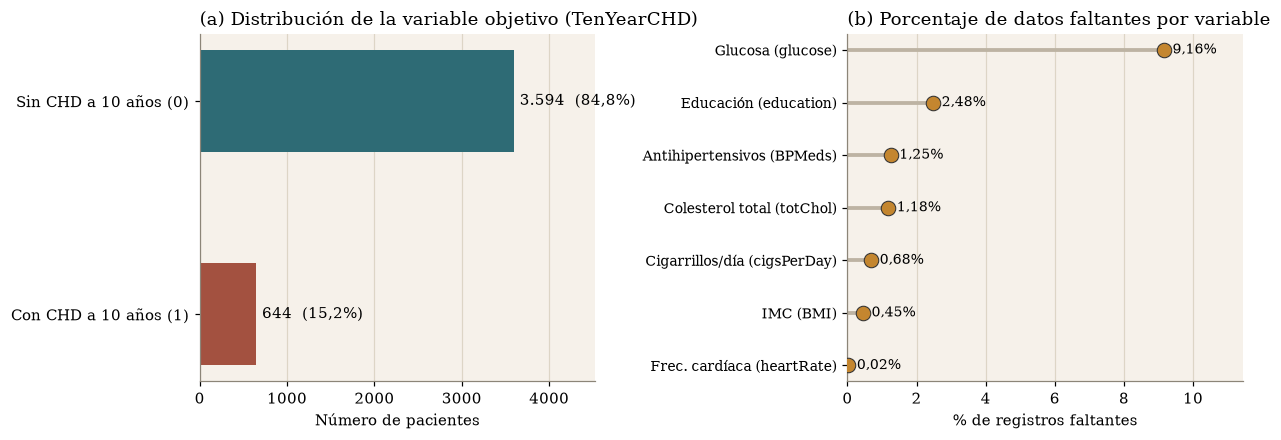

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.1))

# (a) distribución de la variable objetivo (barras horizontales)
vc = df[TARGET].value_counts().sort_index()
labels = ['Sin CHD a 10 años (0)', 'Con CHD a 10 años (1)']
ax[0].barh(labels, vc.values, color=[TEAL, TERRA], height=0.48)
ax[0].invert_yaxis()
for i, v in enumerate(vc.values):
    pct_str = f'{v/n*100:.1f}%'.replace('.', ',')
    cnt_str = f'{v:,}'.replace(',', '.')
    ax[0].text(v + 70, i, f'{cnt_str}  ({pct_str})', va='center', fontsize=9.5)
ax[0].set_xlim(0, vc.max() * 1.26)
ax[0].set_xlabel('Número de pacientes')
ax[0].set_title('(a) Distribución de la variable objetivo (TenYearCHD)')
ax[0].grid(axis='y', visible=False)

# (b) porcentaje de faltantes por variable (lollipop horizontal)
miss_pct = (df.isna().mean() * 100).sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]
nombres_miss = {
    'glucose': 'Glucosa (glucose)',
    'education': 'Educación (education)',
    'BPMeds': 'Antihipertensivos (BPMeds)',
    'totChol': 'Colesterol total (totChol)',
    'cigsPerDay': 'Cigarrillos/día (cigsPerDay)',
    'BMI': 'IMC (BMI)',
    'heartRate': 'Frec. cardíaca (heartRate)'
}
y = np.arange(len(miss_pct))
ax[1].hlines(y, 0, miss_pct.values, color=STEM, lw=2.5)
ax[1].scatter(miss_pct.values, y, s=90, color=OCHRE, edgecolor='#333333', linewidth=0.7, zorder=3)
for i, v in enumerate(miss_pct.values):
    ax[1].text(v + 0.25, i, f'{v:.2f}%'.replace('.', ','), va='center', fontsize=9)
ax[1].set_yticks(y)
ax[1].set_yticklabels([nombres_miss[c] for c in miss_pct.index], fontsize=9)
ax[1].invert_yaxis()
ax[1].set_xlim(0, miss_pct.max() * 1.25)
ax[1].set_xlabel('% de registros faltantes')
ax[1].set_title('(b) Porcentaje de datos faltantes por variable')
ax[1].grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig('fig_panorama.png', bbox_inches='tight')
plt.show()

### Figura 2 - Distribución de tres variables cuantitativas representativas
La glucosa en sangre (`glucose`) presenta una cota a su derecha muy extendida hasta 394 mg/dL (asimetría de 6,21); por ello se grafica recortada al percentil 99 (`≤ 170 mg/dL`) solo para visualizar con claridad el cuerpo de la distribución, manteniendo todos los datos en los cálculos.

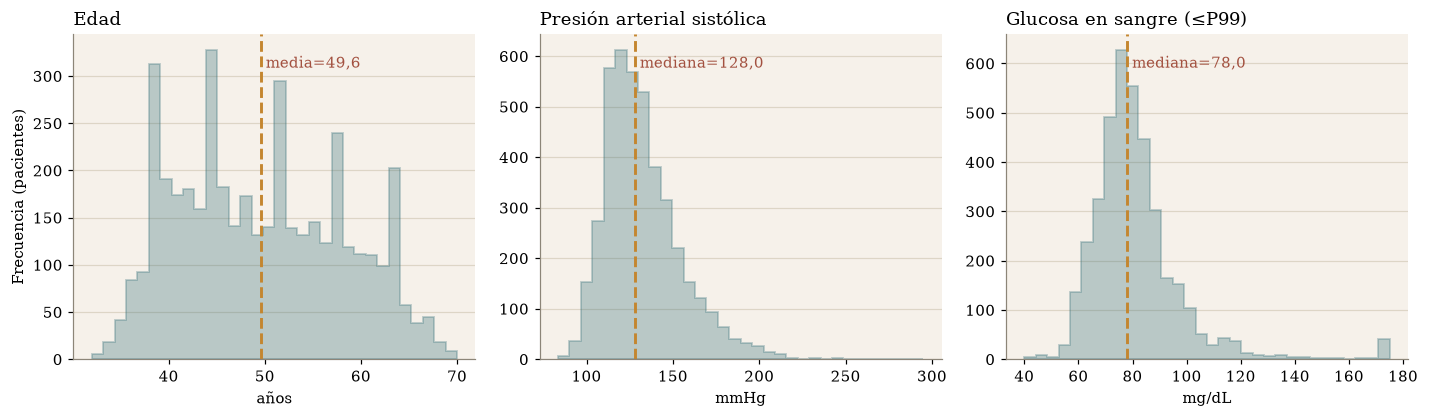

In [10]:
glu_valid = df['glucose'].dropna()
chol_valid = df['totChol'].dropna()
paneles = [
    (df['age'], 'Edad', 'años', 'media', df['age'].mean()),
    (df['sysBP'], 'Presión arterial sistólica', 'mmHg', 'mediana', df['sysBP'].median()),
    (glu_valid.clip(upper=glu_valid.quantile(0.99)), 'Glucosa en sangre (≤P99)', 'mg/dL', 'mediana', glu_valid.median()),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (x, titulo, xlab, nombre, ref) in zip(axes, paneles):
    ax.hist(x, bins=32, histtype='stepfilled', color=TEAL, alpha=0.30,
            edgecolor=TEAL, linewidth=1.2)
    ax.axvline(ref, color=OCHRE, ls='--', lw=1.9)
    txt_ref = f' {nombre}={ref:.1f}'.replace('.', ',')
    ax.text(ref, ax.get_ylim()[1] * 0.91, txt_ref, color=TERRA, fontsize=9.5, va='center')
    ax.set_title(titulo)
    ax.set_xlabel(xlab)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Frecuencia (pacientes)')

plt.tight_layout()
plt.savefig('fig_distribuciones.png', bbox_inches='tight')
plt.show()

### Figura 3 - Matriz de correlaciones (triángulo inferior)
Se examinan las correlaciones lineales de Pearson entre las variables del estudio para identificar pares altamente colineales (`sysBP` con `diaBP`, `currentSmoker` con `cigsPerDay`, `glucose` con `diabetes`) y su relación con `TenYearCHD`.

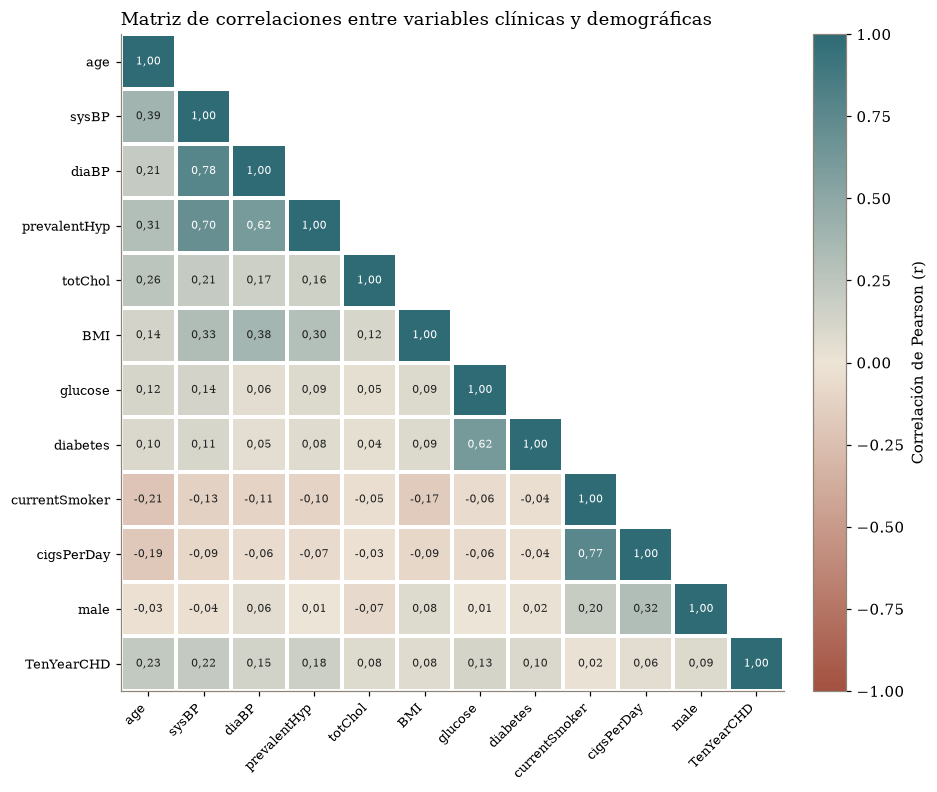

age                0.2253
sysBP              0.2164
prevalentHyp       0.1776
diaBP              0.1453
glucose            0.1255
diabetes           0.0973
male               0.0884
BPMeds             0.0875
totChol            0.0822
BMI                0.0752
prevalentStroke    0.0618
cigsPerDay         0.0579
heartRate          0.0229
currentSmoker      0.0195
education         -0.0541
Name: TenYearCHD, dtype: float64

In [11]:
cols_corr = ['age', 'sysBP', 'diaBP', 'prevalentHyp', 'totChol', 'BMI', 'glucose', 'diabetes', 'currentSmoker', 'cigsPerDay', 'male', 'TenYearCHD']
corr = df[cols_corr].corr()
k = len(corr)
mask = np.triu(np.ones((k, k), dtype=bool), k=1)
cmap = LinearSegmentedColormap.from_list('div', [TERRA, '#ede4d6', TEAL])

fig, ax = plt.subplots(figsize=(8.6, 7.3))
ax.set_facecolor('white')
ax.grid(False)
im = ax.pcolormesh(np.ma.masked_array(corr.values, mask), cmap=cmap, vmin=-1, vmax=1,
                   edgecolors='white', linewidth=1.4)
ax.invert_yaxis()
for i in range(k):
    for j in range(i + 1):
        v = corr.values[i, j]
        if abs(v) < 0.005:
            v = 0.0
        ax.text(j + 0.5, i + 0.5, f'{v:.2f}'.replace('.', ','), ha='center', va='center', fontsize=7.5,
                color='white' if abs(v) > 0.48 else '#222222')
ax.set_xticks(np.arange(k) + 0.5)
ax.set_xticklabels(cols_corr, rotation=45, ha='right', fontsize=8.5)
ax.set_yticks(np.arange(k) + 0.5)
ax.set_yticklabels(cols_corr, fontsize=8.5)
ax.set_title('Matriz de correlaciones entre variables clínicas y demográficas')
cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label('Correlación de Pearson (r)')

plt.tight_layout()
plt.savefig('fig_correlacion.png', bbox_inches='tight')
plt.show()

# Correlación ordenada con respecto a TenYearCHD
df.corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(4)

## 2. Estimación puntual e intervalos de confianza

Se estiman cinco parámetros poblacionales relevantes con un nivel de confianza del 95 % mediante la aproximación normal avalada por el Teorema Central del Límite ($n = 4.238$):

- Media poblacional: $\bar{x} \pm z_{0,975} \cdot s/\sqrt{n}$ (edad, presión arterial sistólica, colesterol total y glucosa en sangre).
- Proporción poblacional de enfermedad coronaria a 10 años (`TenYearCHD`): $\hat{p} \pm z_{0,975} \cdot \sqrt{\hat{p}(1-\hat{p})/n}$ (método de Wald, contrastado con el intervalo de Wilson).

In [12]:
z975 = stats.norm.ppf(0.975)

def ic_media(x):
    x = pd.Series(x).dropna()
    nn = len(x)
    m, s = x.mean(), x.std(ddof=1)
    ee = s / np.sqrt(nn)
    return m, m - z975 * ee, m + z975 * ee, ee, nn

def ic_proporcion_wald(x):
    p, nn = x.mean(), len(x)
    ee = np.sqrt(p * (1 - p) / nn)
    return p, p - z975 * ee, p + z975 * ee, ee, nn

def ic_proporcion_wilson(x):
    p, nn = x.mean(), len(x)
    denom = 1 + z975**2 / nn
    centro = (p + z975**2 / (2 * nn)) / denom
    margen = (z975 / denom) * np.sqrt(p * (1 - p) / nn + z975**2 / (4 * nn**2))
    return centro - margen, centro + margen

filas = []
for nombre, res in [
    ('Edad media (años)', ic_media(df['age'])),
    ('Presión arterial sistólica media (mmHg)', ic_media(df['sysBP'])),
    ('Colesterol total medio (mg/dL)', ic_media(df['totChol'])),
    ('Glucosa media en sangre (mg/dL)', ic_media(df['glucose'])),
    ('Proporción de enfermedad coronaria a 10 años', ic_proporcion_wald(df[TARGET])),
]:
    filas.append({
        'Parámetro': nombre,
        'Estimación puntual': res[0],
        'Error estándar (EE)': res[3],
        'IC 95% inf.': res[1],
        'IC 95% sup.': res[2],
        'n': res[4]
    })
tabla_ic = pd.DataFrame(filas).set_index('Parámetro')
w_inf, w_sup = ic_proporcion_wilson(df[TARGET])
print(f"IC 95% Wilson para proporción de TenYearCHD: [{w_inf:.5f}; {w_sup:.5f}] ([{w_inf*100:.2f}%; {w_sup*100:.2f}%])")
tabla_ic.round(4)

IC 95% Wilson para proporción de TenYearCHD: [0.14147; 0.16308] ([14.15%; 16.31%])


,Estimación puntual,Error estándar (EE),IC 95% inf.,IC 95% sup.,n
Parámetro,,,,,
Edad media (años),49.5849,0.1317,49.3269,49.8430,4238
Presión arterial sistólica media (mmHg),132.3524,0.3385,131.6889,133.0159,4238
Colesterol total medio (mg/dL),236.7216,0.6890,235.3711,238.0721,4188
Glucosa media en sangre (mg/dL),81.9668,0.3862,81.2099,82.7236,3850
Proporción de enfermedad coronaria a 10 años,0.1520,0.0055,0.1412,0.1628,4238


## 3. Pruebas de hipótesis

Nivel de significancia fijado en $\alpha = 0{,}05$.

### 3.1 Prueba *t* de Welch: edad, presión sistólica, colesterol y glucosa según riesgo coronario a 10 años
- $H_0:\ \mu_{\text{CHD}} = \mu_{\text{sin CHD}}$ vs. $H_1:\ \mu_{\text{CHD}} \neq \mu_{\text{sin CHD}}$.
- Se verifica la igualdad de varianzas con la prueba de Levene y se aplica la prueba *t* de Welch (`equal_var=False`), acompañada del tamaño del efecto *d* de Cohen.

In [13]:
for col, etiqueta, unidad in [
    ('age', 'Edad', 'años'),
    ('sysBP', 'Presión sistólica', 'mmHg'),
    ('totChol', 'Colesterol total', 'mg/dL'),
    ('glucose', 'Glucosa en sangre', 'mg/dL')
]:
    g1 = df.loc[df[TARGET] == 1, col].dropna()
    g0 = df.loc[df[TARGET] == 0, col].dropna()
    lev_stat, lev_p = stats.levene(g1, g0)
    t_stat, p_val = stats.ttest_ind(g1, g0, equal_var=False)
    n1_, n0_ = len(g1), len(g0)
    sp = np.sqrt(((n1_ - 1) * g1.var(ddof=1) + (n0_ - 1) * g0.var(ddof=1)) / (n1_ + n0_ - 2))
    d_cohen = (g1.mean() - g0.mean()) / sp
    print(f"=== {etiqueta} ({unidad}) ===")
    print(f"  Con CHD (n={n1_:,}) : media = {g1.mean():.2f}, DE = {g1.std(ddof=1):.2f}, mediana = {g1.median():.2f}")
    print(f"  Sin CHD (n={n0_:,}) : media = {g0.mean():.2f}, DE = {g0.std(ddof=1):.2f}, mediana = {g0.median():.2f}")
    print(f"  Levene F = {lev_stat:.2f} (p = {lev_p:.4e}) | t de Welch = {t_stat:.2f}, p = {p_val:.4e}, d de Cohen = {d_cohen:.3f}")

=== Edad (años) ===
  Con CHD (n=644) : media = 54.15, DE = 8.01, mediana = 55.00
  Sin CHD (n=3,594) : media = 48.77, DE = 8.41, mediana = 48.00
  Levene F = 3.73 (p = 5.3455e-02) | t de Welch = 15.58, p = 1.0406e-48, d de Cohen = 0.644
=== Presión sistólica (mmHg) ===
  Con CHD (n=644) : media = 143.62, DE = 26.69, mediana = 139.00
  Sin CHD (n=3,594) : media = 130.33, DE = 20.46, mediana = 127.00
  Levene F = 65.21 (p = 8.6923e-16) | t de Welch = 12.02, p = 1.2096e-30, d de Cohen = 0.617
=== Colesterol total (mg/dL) ===
  Con CHD (n=635) : media = 245.39, DE = 48.08, mediana = 241.00
  Sin CHD (n=3,553) : media = 235.17, DE = 43.77, mediana = 232.00
  Levene F = 3.00 (p = 8.3154e-02) | t de Welch = 5.00, p = 7.0742e-07, d de Cohen = 0.230
=== Glucosa en sangre (mg/dL) ===
  Con CHD (n=594) : media = 89.01, DE = 41.14, mediana = 79.00
  Sin CHD (n=3,256) : media = 80.68, DE = 18.97, mediana = 78.00
  Levene F = 65.53 (p = 7.5978e-16) | t de Welch = 4.84, p = 1.6324e-06, d de Cohen = 

### 3.2 Prueba $\chi^2$ de independencia: tramo etario y enfermedad coronaria a 10 años
Se clasifica la edad de la cohorte (32 a 70 años) en cuatro tramos decenales (`32–39`, `40–49`, `50–59` y `60–70` años) y se contrasta su independencia respecto al evento `TenYearCHD`.

In [14]:
tramos = pd.cut(
    df['age'],
    bins=[30, 40, 50, 60, 75],
    labels=['32-39', '40-49', '50-59', '60-70'],
    right=False
)
tabla_edad = pd.crosstab(tramos, df[TARGET])
chi2_e, p_chi_e, gl_e, esp_e = stats.chi2_contingency(tabla_edad)
V_e = np.sqrt(chi2_e / (tabla_edad.values.sum() * (min(tabla_edad.shape) - 1)))

print(f"Chi² = {chi2_e:,.2f}   gl = {gl_e}   valor p = {p_chi_e:.4e} (< 0.0001)   V de Cramér = {V_e:.3f}")
print(f"Frecuencia esperada mínima: {esp_e.min():.2f} (cumple holgadamente el supuesto >= 5)")
tasa_edad = tramos.to_frame('tramo').assign(y=df[TARGET]).groupby('tramo', observed=True)['y'].agg(['count', 'sum', 'mean'])
tasa_edad['% CHD'] = (tasa_edad['mean'] * 100).round(2)
tasa_edad[['count', 'sum', '% CHD']]

Chi² = 191.31   gl = 3   valor p = 3.1854e-41 (< 0.0001)   V de Cramér = 0.212
Frecuencia esperada mínima: 84.34 (cumple holgadamente el supuesto >= 5)


,count,sum,% CHD
tramo,,,
32-39,555,23,4.14
40-49,1660,167,10.06
50-59,1333,263,19.73
60-70,690,191,27.68


### Figura 4 - Tasa de enfermedad coronaria a 10 años por tramo etario y por cuartil de presión sistólica

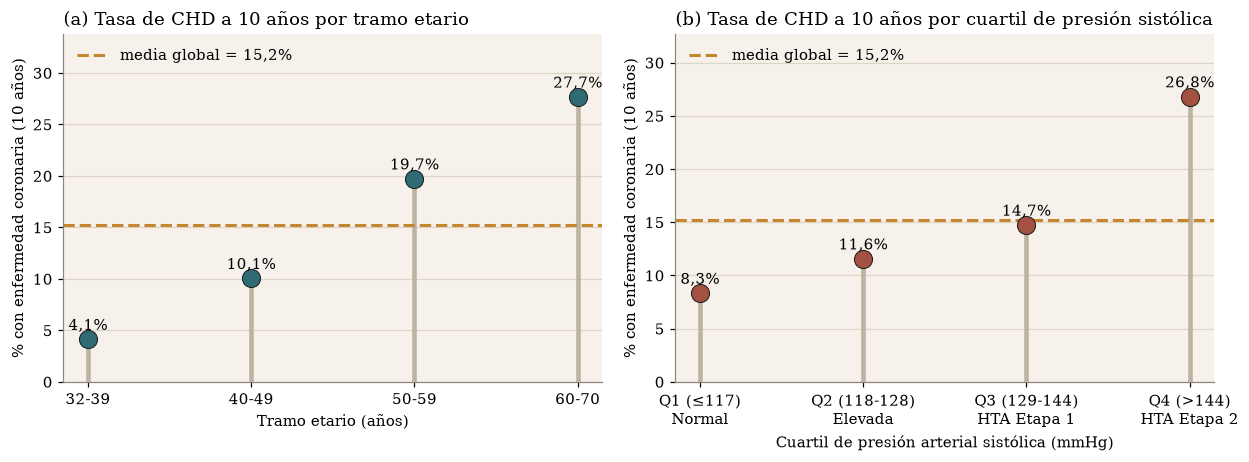

In [15]:
media_global = df[TARGET].mean() * 100

cuartil_sbp = pd.qcut(
    df['sysBP'], q=4,
    labels=['Q1 (≤117)\nNormal', 'Q2 (118-128)\nElevada', 'Q3 (129-144)\nHTA Etapa 1', 'Q4 (>144)\nHTA Etapa 2']
)
tasa_sbp = cuartil_sbp.to_frame('q_sbp').assign(y=df[TARGET]).groupby('q_sbp', observed=True)['y'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

# Panel (a): por tramo etario
x1 = np.arange(len(tasa_edad))
v1 = tasa_edad['mean'].values * 100
axes[0].vlines(x1, 0, v1, color=STEM, lw=3)
axes[0].scatter(x1, v1, s=140, color=TEAL, edgecolor='#222222', linewidth=0.7, zorder=3)
for xi, val in zip(x1, v1):
    axes[0].text(xi, val + 0.9, f'{val:.1f}%'.replace('.', ','), ha='center', fontsize=9.5)
axes[0].axhline(media_global, color=OCHRE, ls='--', lw=2, label=f'media global = {media_global:.1f}%'.replace('.', ','))
axes[0].set_xticks(x1)
axes[0].set_xticklabels(tasa_edad.index)
axes[0].set_xlabel('Tramo etario (años)')
axes[0].set_ylabel('% con enfermedad coronaria (10 años)')
axes[0].set_ylim(0, v1.max() * 1.22)
axes[0].set_title('(a) Tasa de CHD a 10 años por tramo etario')
axes[0].legend(frameon=False, loc='upper left')
axes[0].grid(axis='x', visible=False)

# Panel (b): por cuartil de presión arterial sistólica
x2 = np.arange(len(tasa_sbp))
v2 = tasa_sbp.values
axes[1].vlines(x2, 0, v2, color=STEM, lw=3)
axes[1].scatter(x2, v2, s=140, color=TERRA, edgecolor='#222222', linewidth=0.7, zorder=3)
for xi, val in zip(x2, v2):
    axes[1].text(xi, val + 0.9, f'{val:.1f}%'.replace('.', ','), ha='center', fontsize=9.5)
axes[1].axhline(media_global, color=OCHRE, ls='--', lw=2, label=f'media global = {media_global:.1f}%'.replace('.', ','))
axes[1].set_xticks(x2)
axes[1].set_xticklabels(tasa_sbp.index)
axes[1].set_xlabel('Cuartil de presión arterial sistólica (mmHg)')
axes[1].set_ylabel('% con enfermedad coronaria (10 años)')
axes[1].set_ylim(0, v2.max() * 1.22)
axes[1].set_title('(b) Tasa de CHD a 10 años por cuartil de presión sistólica')
axes[1].legend(frameon=False, loc='upper left')
axes[1].grid(axis='x', visible=False)

plt.tight_layout()
plt.savefig('fig_chd_edad.png', bbox_inches='tight')
plt.show()

### 3.3 Prueba *z* de dos proporciones y $\chi^2$: hipertensión prevalente, diabetes y sexo
Se contrasta si la proporción de enfermedad coronaria a 10 años difiere significativamente según la presencia de hipertensión arterial prevalente (`prevalentHyp`), diabetes (`diabetes`) y sexo masculino (`male`), cuantificando el Riesgo Relativo ($\text{RR} = \hat{p}_1 / \hat{p}_0$) y la Razón de Momios ($\text{OR}$).

In [16]:
for col, nombre in [
    ('prevalentHyp', 'Hipertensión arterial prevalente'),
    ('diabetes', 'Diabetes mellitus'),
    ('male', 'Sexo masculino')
]:
    g1 = df.loc[df[col] == 1, TARGET]
    g0 = df.loc[df[col] == 0, TARGET]
    p1, p0 = g1.mean(), g0.mean()
    n1, n0 = len(g1), len(g0)
    p_comb = (g1.sum() + g0.sum()) / (n1 + n0)
    z_stat = (p1 - p0) / np.sqrt(p_comb * (1 - p_comb) * (1 / n1 + 1 / n0))
    p_z = 2 * stats.norm.sf(abs(z_stat))
    rr = p1 / p0
    or_val = (p1 / (1 - p1)) / (p0 / (1 - p0))
    tab = pd.crosstab(df[col], df[TARGET])
    chi2_c, p_c, gl_c, esp_c = stats.chi2_contingency(tab)
    v_c = np.sqrt(chi2_c / (n * 1))
    print(f"=== {nombre} ({col}) ===")
    print(f"  Con condición (1): {p1*100:.2f}% ({g1.sum()}/{n1:,}) | Sin condición (0): {p0*100:.2f}% ({g0.sum()}/{n0:,})")
    print(f"  z = {z_stat:.2f}, p = {p_z:.4e} | Chi² = {chi2_c:.2f} (frec. esp. mín. = {esp_c.min():.1f}), V de Cramér = {v_c:.3f}")
    print(f"  Riesgo Relativo (RR) = {rr:.2f}x | Razón de Momios (OR) = {or_val:.2f}")

=== Hipertensión arterial prevalente (prevalentHyp) ===
  Con condición (1): 24.70% (325/1,316) | Sin condición (0): 10.92% (319/2,922)
  z = 11.56, p = 6.4253e-31 | Chi² = 132.61 (frec. esp. mín. = 200.0), V de Cramér = 0.177
  Riesgo Relativo (RR) = 2.26x | Razón de Momios (OR) = 2.68
=== Diabetes mellitus (diabetes) ===
  Con condición (1): 36.70% (40/109) | Sin condición (0): 14.63% (604/4,129)
  z = 6.34, p = 2.3688e-10 | Chi² = 38.44 (frec. esp. mín. = 16.6), V de Cramér = 0.095
  Riesgo Relativo (RR) = 2.51x | Razón de Momios (OR) = 3.38
=== Sexo masculino (male) ===
  Con condición (1): 18.86% (343/1,819) | Sin condición (0): 12.44% (301/2,419)
  z = 5.76, p = 8.5811e-09 | Chi² = 32.64 (frec. esp. mín. = 276.4), V de Cramér = 0.088
  Riesgo Relativo (RR) = 1.52x | Razón de Momios (OR) = 1.64


### Figura 5 - Presión sistólica por grupo y escalada de riesgo por factores cardiovasculares acumulados
Se define el conteo de factores de riesgo cardiovascular clásicos de Framingham acumulados por paciente (`0` a `4`): hipertensión prevalente (`prevalentHyp = 1`), hipercolesterolemia (`totChol >= 240 mg/dL`), tabaquismo activo (`currentSmoker = 1`) y diabetes o hiperglucemia (`diabetes = 1` o `glucose >= 126 mg/dL`).

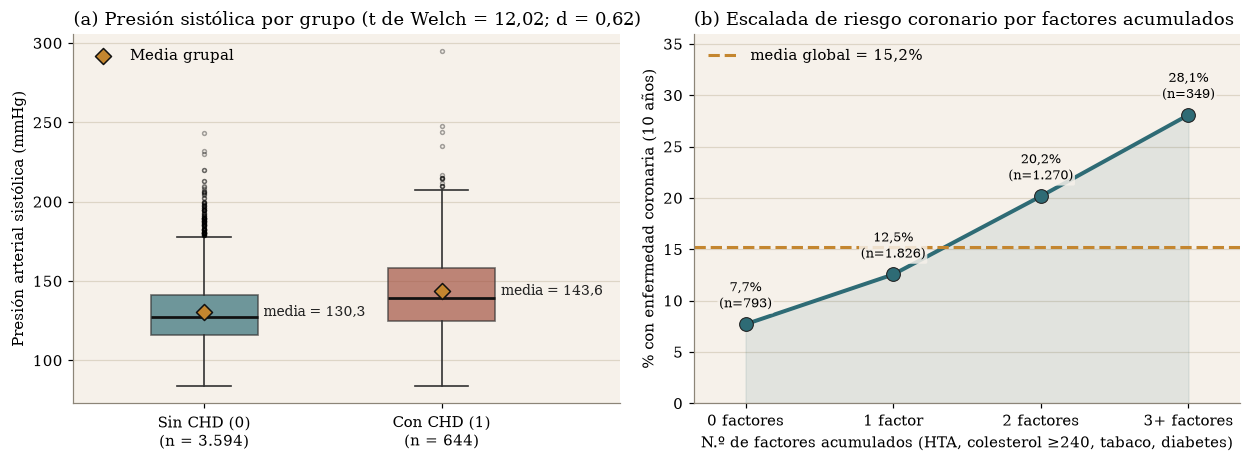

,count,sum,% CHD
tramo_factores,,,
0,793,61,7.69
1,1826,229,12.54
2,1270,256,20.16
3,349,98,28.08


In [17]:
df['n_factores'] = (
    df['prevalentHyp']
    + (df['totChol'] >= 240).astype(int)
    + df['currentSmoker']
    + ((df['diabetes'] == 1) | (df['glucose'] >= 126)).astype(int)
)
# Agrupamos 3 y 4 factores en '3+ factores' para asegurar tamaño muestral alto en cada punto
df['tramo_factores'] = df['n_factores'].clip(upper=3)
tasa_fac = df.groupby('tramo_factores')[TARGET].agg(['count', 'sum', 'mean'])
tasa_fac['% CHD'] = tasa_fac['mean'] * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

# Panel (a): Boxplot de presión sistólica según ocurrencia de CHD (con rombo en la media)
datos_sbp = [df.loc[df[TARGET] == 0, 'sysBP'], df.loc[df[TARGET] == 1, 'sysBP']]
bp = axes[0].boxplot(
    datos_sbp, widths=0.45, patch_artist=True,
    medianprops=dict(color='#111111', lw=1.8),
    boxprops=dict(edgecolor='#333333', lw=1.1),
    whiskerprops=dict(color='#333333', lw=1.1),
    capprops=dict(color='#333333', lw=1.1),
    flierprops=dict(marker='o', markersize=2.5, alpha=0.35)
)
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(['Sin CHD (0)\n(n = 3.594)', 'Con CHD (1)\n(n = 644)'])
axes[0].set_xlim(0.45, 2.75)
for patch, col in zip(bp['boxes'], [TEAL, TERRA]):
    patch.set_facecolor(col)
    patch.set_alpha(0.68)
medias_s = [g.mean() for g in datos_sbp]
axes[0].scatter([1, 2], medias_s, marker='D', s=55, color=OCHRE, edgecolor='#111111', zorder=4, label='Media grupal')
for idx_m, m_val in enumerate(medias_s, start=1):
    axes[0].text(idx_m + 0.25, m_val, f'media = {m_val:.1f}'.replace('.', ','), va='center', fontsize=9, color='#222222')
axes[0].set_ylabel('Presión arterial sistólica (mmHg)')
axes[0].set_title('(a) Presión sistólica por grupo (t de Welch = 12,02; d = 0,62)')
axes[0].legend(frameon=False, loc='upper left')
axes[0].grid(axis='x', visible=False)

# Panel (b): Curva de escalada de CHD según número de factores de riesgo acumulados
idx_f = tasa_fac.index.values
val_f = tasa_fac['% CHD'].values
axes[1].fill_between(idx_f, val_f, color=TEAL, alpha=0.10)
axes[1].plot(idx_f, val_f, color=TEAL, lw=2.6, marker='o', ms=9,
             markeredgecolor='#222222', markeredgewidth=0.7)
for xi, v, cnt in zip(idx_f, val_f, tasa_fac['count'].values):
    pct_s = f'{v:.1f}%'.replace('.', ',')
    cnt_s = f'{cnt:,}'.replace(',', '.')
    axes[1].text(
        xi, v + 1.2, f'{pct_s}\n(n={cnt_s})',
        ha='center', va='bottom', fontsize=8.8,
        bbox=dict(boxstyle='round,pad=0.12', facecolor=BG, edgecolor='none', alpha=0.85)
    )
axes[1].axhline(media_global, color=OCHRE, ls='--', lw=2, label=f'media global = {media_global:.1f}%'.replace('.', ','))
axes[1].set_xlim(-0.35, 3.35)
axes[1].set_ylim(0, max(val_f) * 1.28)
axes[1].set_xticks([0, 1, 2, 3])
axes[1].set_xticklabels(['0 factores', '1 factor', '2 factores', '3+ factores'])
axes[1].set_xlabel('N.º de factores acumulados (HTA, colesterol ≥240, tabaco, diabetes)')
axes[1].set_ylabel('% con enfermedad coronaria (10 años)')
axes[1].set_title('(b) Escalada de riesgo coronario por factores acumulados')
axes[1].legend(frameon=False, loc='upper left')
axes[1].grid(axis='x', visible=False)

plt.tight_layout()
plt.savefig('fig_chd_factores.png', bbox_inches='tight')
plt.show()
tasa_fac[['count', 'sum', '% CHD']].round(2)

## 4. Síntesis de hallazgos para el informe

- **Descriptiva y calidad de datos:** Muestra de $n = 4.238$ participantes del *Framingham Heart Study* con desbalance en la variable objetivo (`15,20 %` desarrolló enfermedad coronaria a 10 años, 644 casos). Existen datos faltantes en siete variables (`13,73 %` de las filas tiene al menos un vacío), liderados por `glucose` (`9,16 %`, 388 casos) y `education` (`2,48 %`, 105 casos), mientras que los 29 faltantes de `cigsPerDay` (`0,68 %`) ocurren exclusivamente en fumadores activos (`currentSmoker = 1`, mecanismo MAR). Existen colinealidades fuertes entre `sysBP` y `diaBP` ($r = 0{,}78$) y entre `currentSmoker` y `cigsPerDay` ($r = 0{,}77$).
- **Estimación puntual e IC 95 %:** Intervalos precisos avalados por el TCL: edad media `49,58` años `[49,33; 49,84]`, presión sistólica media `132,35 mmHg` `[131,69; 133,02]`, colesterol total medio `236,72 mg/dL` `[235,37; 238,07]` ($n = 4.188$), glucosa media `81,97 mg/dL` `[81,21; 82,72]` ($n = 3.850$) y proporción de CHD a 10 años `15,20 %` `[14,12 %; 16,28 %]`.
- **Pruebas de hipótesis:** La edad (`54,15` vs. `48,77` años; $t_{\text{Welch}} = 15,58$, $p < 0,0001$, $d = 0,64$) y la presión arterial sistólica (`143,62` vs. `130,33 mmHg`; $t_{\text{Welch}} = 12,02$, $p < 0,0001$, $d = 0,62$) son los predictores continuos con mayor poder discriminante. Entre los factores categóricos, la hipertensión prevalente duplica con creces el riesgo coronario (`24,70 %` vs. `10,92 %`; $\text{RR} = 2,26$, $\chi^2 = 132,61$, $p < 0,0001$) y la diabetes lo multiplica por 2,5 (`36,70 %` vs. `14,63 %`; $\text{RR} = 2,51$, $p < 0,0001$).

In [18]:
print('Figuras generadas:', sorted(f for f in os.listdir('.') if f.startswith('fig_') and f.endswith('.png')))

Figuras generadas: ['fig_chd_edad.png', 'fig_chd_factores.png', 'fig_correlacion.png', 'fig_distribuciones.png', 'fig_panorama.png']
